# iTransformer — FS05_METALS_EXO — Five seeds 41–45

This is the standalone FS05 version of the iTransformer notebook. It follows the original FS05 setup and adds five-seed training and resumable job checkpoints.

- Input feature set: **FS05_METALS_EXO = Aluminium, Tin, Silver, Gold (K=4)**. Copper is the forecast target and is **excluded from the network input**. The model uses the previous 22 sessions `t−22 ... t−1` to predict `Copper(t)`.
- For the Residual objective, previous observed Copper is used only in the final reconstruction `ŷ_t = y_(t−1) + Δŷ_t`; it is not fed into the iTransformer.
- Workload: 4 split ratios × 3 training schemes × 2 objectives × 5 seeds = **120 neural fits**, plus **12 shared Naive baselines**.
- Seeds: **41, 42, 43, 44, 45**. Seed 42 outputs are exported separately for comparison with earlier results.
- Each completed job saves its metrics and date-level predictions. The training cell skips valid jobs and refreshes a recovery ZIP every 40 completed neural fits.

In Kaggle, attach `dataset_9_commodities_daily.csv`, enable a GPU, then run all cells. If Kaggle resets, attach the latest recovery ZIP as an input, set `RESUME_ZIP_PATH` in Configuration, and run from the top.

**Architecture:** inverted embedding `(22,4) → (4,48)`, two encoder blocks, four attention heads, key dimension 12, feed-forward layers 96→48, flatten `(4×48=192)`, Dense(32, GELU), dropout 0.1, Dense(1, linear). Attention operates across the Aluminium, Tin, Silver, and Gold variable tokens.


## 1. Configuration

This notebook is pinned to **FS05_METALS_EXO only** and defaults to seeds 41–45. It trains all **120 remaining iTransformer jobs** and saves **12 Naive baselines**. `MAX_NEW_FITS` can cap a run into smaller batches; completed jobs are skipped when training resumes.


In [1]:
from pathlib import Path
import os, gc, json, time, zipfile, hashlib, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from scipy.stats import t as student_t
from IPython.display import display

CUSTOM_CSV_PATH = ''       # Optional absolute path to CSV.
EXPECTED_SHA256 = ''       # Optional raw file hash check.
RESUME_ZIP_PATH = ''       # Optional prior checkpoint ZIP after a Kaggle reset.
MAX_NEW_FITS = None        # None = run every unfinished fit; integer = optional batch cap.
REQUIRE_COMPLETE = True    # Refuse exports until all selected FS01 jobs and baselines exist.
CHECKPOINT_EVERY_FITS = 40 # Refresh the resumable ZIP every 40 completed neural fits.
FEATURE_SET_FILTER = ['FS05_METALS_EXO']  # This notebook runs FS05 only.
SEED_FILTER = None         # None = all five seeds 41..45; or [42] for a one-seed run.

LOOKBACK, HORIZON, TARGET = 22, 1, 'Copper'
SEEDS = (41, 42, 43, 44, 45)
BATCH_SIZE, EPOCHS, PATIENCE = 64, 65, 9
RATIOS = (0.80, 0.90, 0.925, 0.95)
SCHEMES = ('expanding', 'rolling_756', 'recency_weighted')
RECENCY_HALF_LIFE = 252
OBJECTIVES = ('direct', 'residual')
EMBED_DIM, ENCODER_LAYERS, ATTENTION_HEADS, HEAD_KEY_DIM = 48, 2, 4, 12
FF_DIM, DROPOUT, HEAD_UNITS = 96, 0.10, 32
LEARNING_RATE, CLIPNORM = 0.0003, 1.0
DATA_UNION_COLUMNS = ['Copper', 'WTI', 'Gold', 'Silver', 'Aluminium', 'Tin']
SOURCE_DATASET_NAME = 'dataset_9_commodities_daily.csv'
FEATURE_SETS = {
 'FS01_CU':['Copper'],
 'FS02_PAPER_CU':['Copper','WTI','Gold','Silver'],
 'FS03_PAPER_EXO':['WTI','Gold','Silver'],
 'FS04_METALS_CU':['Copper','Aluminium','Tin','Silver','Gold'],
 'FS05_METALS_EXO':['Aluminium','Tin','Silver','Gold'],
 'FS06_WTI_CU':['Copper','Aluminium','Tin','WTI'],
}
ACTIVE_FS = list(FEATURE_SETS) if FEATURE_SET_FILTER is None else list(FEATURE_SET_FILTER)
ACTIVE_SEEDS = list(SEEDS) if SEED_FILTER is None else list(SEED_FILTER)
assert set(ACTIVE_FS).issubset(FEATURE_SETS) and set(ACTIVE_SEEDS).issubset(SEEDS)
assert LOOKBACK == 22 and HORIZON == 1
BASE = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
for gpu in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError: pass
print('TensorFlow:',tf.__version__,'| GPU:',tf.config.list_physical_devices('GPU'))
print('Feature sets:',ACTIVE_FS,'| seeds:',ACTIVE_SEEDS,
      '| fit mode:',('all remaining' if MAX_NEW_FITS is None else f'up to {MAX_NEW_FITS} new fits'))


TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Feature sets: ['FS05_METALS_EXO'] | seeds: [41, 42, 43, 44, 45] | fit mode: all remaining


## 2. Load and audit the dataset

This cell locates the attached CSV, checks required columns and dates, applies the shared complete-case filter across all six input commodities, and records a file fingerprint so runs can be compared safely.


In [2]:
candidates = ([Path(CUSTOM_CSV_PATH).expanduser()] if CUSTOM_CSV_PATH.strip() else []) + [
 Path('/kaggle/input/datasets/lancelot71000/dataset-9-commodities-daily')/SOURCE_DATASET_NAME,
 Path('/kaggle/input/dataset-9-commodities-daily')/SOURCE_DATASET_NAME,
 Path.cwd()/SOURCE_DATASET_NAME, Path('data/processed')/SOURCE_DATASET_NAME]
found=[p for p in candidates if p.is_file()]
if not found:
    discovered=sorted(Path('/kaggle/input').rglob(SOURCE_DATASET_NAME)) if Path('/kaggle/input').is_dir() else []
    if len(discovered)>1: raise RuntimeError('Multiple CSV files found; set CUSTOM_CSV_PATH: '+str(discovered))
    found=discovered
if not found: raise FileNotFoundError('Attach a Kaggle input containing '+SOURCE_DATASET_NAME+' or set CUSTOM_CSV_PATH.')
data_path=found[0]
DATA_SHA256=hashlib.sha256(data_path.read_bytes()).hexdigest()
if EXPECTED_SHA256 and EXPECTED_SHA256.lower()!=DATA_SHA256.lower(): raise RuntimeError('SHA-256 mismatch: '+DATA_SHA256)
raw=pd.read_csv(data_path)
needed=['Date']+DATA_UNION_COLUMNS
if set(needed)-set(raw.columns): raise KeyError('Missing columns: '+str(sorted(set(needed)-set(raw.columns))))
raw['Date']=pd.to_datetime(raw['Date'],errors='coerce')
if raw.Date.isna().any() or raw.Date.duplicated().any(): raise ValueError('Date is missing, invalid, or duplicated.')
raw=raw.sort_values('Date').reset_index(drop=True)
for c in DATA_UNION_COLUMNS: raw[c]=pd.to_numeric(raw[c],errors='coerce')
quality=pd.DataFrame({'feature':DATA_UNION_COLUMNS,
 'missing_before_filter':[int(raw[c].isna().sum()) for c in DATA_UNION_COLUMNS],
 'nonpositive_before_filter':[int((raw[c]<=0).sum()) for c in DATA_UNION_COLUMNS]})
data=raw.dropna(subset=DATA_UNION_COLUMNS).reset_index(drop=True)
arr=data[DATA_UNION_COLUMNS].to_numpy(np.float64)
if len(data)<500 or not np.isfinite(arr).all() or not (arr>0).all(): raise ValueError('Dataset quality checks failed.')
RUN_CONFIG={'script':'itransformer_fs05_5seeds_v1','sha256':DATA_SHA256,'rows':len(data),
 'date_start':str(data.Date.iloc[0].date()),'date_end':str(data.Date.iloc[-1].date()),
 'active_feature_sets':ACTIVE_FS,'feature_sets':{fs:FEATURE_SETS[fs] for fs in ACTIVE_FS},
 'seeds':ACTIVE_SEEDS,'lookback':LOOKBACK,'horizon':HORIZON,
 'ratios':RATIOS,'schemes':SCHEMES,'half_life':RECENCY_HALF_LIFE,'batch':BATCH_SIZE,
 'epochs':EPOCHS,'patience':PATIENCE,'embed':EMBED_DIM,'encoders':ENCODER_LAYERS,
 'heads':ATTENTION_HEADS,'key_dim':HEAD_KEY_DIM,'ff':FF_DIM,'dropout':DROPOUT,
 'head':HEAD_UNITS,'lr':LEARNING_RATE,'clipnorm':CLIPNORM,'union_columns':DATA_UNION_COLUMNS}
CONFIG_HASH=hashlib.sha256(json.dumps(RUN_CONFIG,sort_keys=True).encode()).hexdigest()[:12]
RUN_KEY=f'itransformer_fs05_5seed_{CONFIG_HASH}_sha{DATA_SHA256[:8]}'
OUT=BASE/'iTransformer_FS05_5Seeds'/RUN_KEY
(OUT/'jobs').mkdir(parents=True,exist_ok=True); (OUT/'figures').mkdir(parents=True,exist_ok=True)
(OUT/'config.json').write_text(json.dumps(RUN_CONFIG,ensure_ascii=False,indent=2),encoding='utf-8')
quality.to_csv(OUT/'data_quality.csv',index=False)
if RESUME_ZIP_PATH.strip():
    archive=Path(RESUME_ZIP_PATH).expanduser(); root=OUT.resolve()
    if not archive.is_file(): raise FileNotFoundError(archive)
    with zipfile.ZipFile(archive) as zf:
        for name in zf.namelist():
            dest=(OUT/name).resolve()
            if dest!=root and root not in dest.parents: raise ValueError('Unsafe ZIP path: '+name)
        zf.extractall(OUT)
print('CSV:',data_path,'| SHA256:',DATA_SHA256)
print('Rows:',len(data),'| dates:',data.Date.iloc[0].date(),'to',data.Date.iloc[-1].date(),
      '| rows dropped:',len(raw)-len(data),'| output:',OUT)
if len(data)!=2710: print('WARNING: seed-42 outputs in Vi Task report 2710 common rows; check dataset/timeline.')


CSV: /kaggle/input/datasets/tvi3001/dataset-9-commodities-daily/dataset_9_commodities_daily.csv | SHA256: a761a9082de36ad8724597ff1518e24bbf1a61676bd3164676e7f4218d275d83
Rows: 2710 | dates: 2016-01-13 to 2026-11-13 | rows dropped: 0 | output: /kaggle/working/iTransformer_FS05_5Seeds/itransformer_fs05_5seed_ba9f46661575_shaa761a908


## 3. Chronological splits, train-only scalers, and lookback windows

For each ratio and scheme, the validation segment is the last 10% of the pre-test segment. Scalers are fit on training data only. Each example uses the previous 22 sessions to predict the next Copper value; the target timestamp is excluded from its input window.


In [3]:
def make_context(frame, fs, ratio, scheme):
    features=FEATURE_SETS[fs]; n=len(frame); split=int(n*float(ratio)); val_start=int(split*.90)
    fit_start=max(0,val_start-756) if scheme=='rolling_756' else 0
    if scheme not in SCHEMES or not (LOOKBACK+40 < val_start-fit_start and val_start<split<n):
        raise ValueError(f'Invalid/short split: {fs} {ratio} {scheme}')
    # Fit scalers only on the training range, then transform the common chronological series.
    xs=MinMaxScaler().fit(frame.iloc[fit_start:val_start][features])
    ys=MinMaxScaler().fit(frame.iloc[fit_start:val_start][[TARGET]])
    x=xs.transform(frame[features]).astype(np.float32)
    y=ys.transform(frame[[TARGET]]).ravel().astype(np.float32)
    def block(start,end,train=False):
        ids=np.arange(max(start,LOOKBACK),end,dtype=np.int64)
        if train: ids=ids[ids-LOOKBACK>=fit_start]
        ix=ids[:,None]-LOOKBACK+np.arange(LOOKBACK)[None,:]
        assert len(ids) and np.all(ix<ids[:,None]),'Empty window or target leakage'
        result={'idx':ids,'X':x[ix],'y':y[ids],'prev':y[ids-1],'date':frame.Date.iloc[ids].to_numpy()}
        assert result['X'].shape[1:]==(LOOKBACK,len(features))
        assert np.isfinite(result['X']).all() and np.isfinite(result['y']).all()
        if TARGET in features:
            j=features.index(TARGET)
            assert np.allclose(result['X'][:,-1,j],result['prev'],atol=2e-6,rtol=1e-6)
        return result
    tr=block(fit_start,val_start,True); va=block(val_start,split); te=block(split,n)
    assert tr['idx'][-1]<va['idx'][0]<te['idx'][0] and xs.n_samples_seen_==val_start-fit_start
    return {'feature_set':fs,'features':features,'train':tr,'val':va,'test':te,
      'x_scaler':xs,'y_scaler':ys,'ratio':float(ratio),'scheme':scheme,
      'fit_start':fit_start,'val_start':val_start,'split':split}

_contexts={}
def get_context(fs,ratio,scheme):
    key=(fs,float(ratio),scheme)
    if key not in _contexts: _contexts[key]=make_context(data,fs,ratio,scheme)
    return _contexts[key]
for fs in ACTIVE_FS:
    c=get_context(fs,RATIOS[0],SCHEMES[0])
    print(fs,'K=',len(c['features']),'train/val/test=',*[len(c[k]['idx']) for k in ('train','val','test')],
          '| test=',pd.Timestamp(c['test']['date'][0]).date(),'to',pd.Timestamp(c['test']['date'][-1]).date())
print('PASS: PASS: X uses t-22 through t-1; Copper(t) is target only.')

FS05_METALS_EXO K= 4 train/val/test= 1929 217 542 | test= 2024-10-07 to 2026-11-13
PASS: PASS: X uses t-22 through t-1; Copper(t) is target only.


## 4. iTransformer model builder

The custom Keras implementation follows the existing notebook: invert the time and feature axes, embed each variable history, apply two attention encoder blocks, then flatten and predict one scaled target.


In [4]:
def build_itransformer(k,fs):
    inp=tf.keras.Input((LOOKBACK,k),name='past_22_by_K')
    x=tf.keras.layers.Permute((2,1),name='inverted_variable_tokens')(inp) # (B,K,22)
    x=tf.keras.layers.Dense(EMBED_DIM,name='variable_embedding_48')(x)   # (B,K,48)
    for i in range(1,ENCODER_LAYERS+1):
        a=tf.keras.layers.MultiHeadAttention(num_heads=ATTENTION_HEADS,key_dim=HEAD_KEY_DIM,
            dropout=DROPOUT,name=f'encoder{i}_mha')(x,x)
        a=tf.keras.layers.Dropout(DROPOUT,name=f'encoder{i}_attn_dropout')(a)
        x=tf.keras.layers.LayerNormalization(epsilon=1e-6,name=f'encoder{i}_norm1')(
            tf.keras.layers.Add(name=f'encoder{i}_residual1')([x,a]))
        f=tf.keras.layers.Dense(FF_DIM,activation='gelu',name=f'encoder{i}_ffn96')(x)
        f=tf.keras.layers.Dropout(DROPOUT,name=f'encoder{i}_ff_dropout')(f)
        f=tf.keras.layers.Dense(EMBED_DIM,name=f'encoder{i}_ffn48')(f)
        x=tf.keras.layers.LayerNormalization(epsilon=1e-6,name=f'encoder{i}_norm2')(
            tf.keras.layers.Add(name=f'encoder{i}_residual2')([x,f]))
    x=tf.keras.layers.Flatten(name='flatten_Kx48')(x)
    x=tf.keras.layers.Dense(HEAD_UNITS,activation='gelu',name='head_dense32')(x)
    x=tf.keras.layers.Dropout(DROPOUT,name='head_dropout')(x)
    out=tf.keras.layers.Dense(1,activation='linear',name='scaled_copper')(x)
    model=tf.keras.Model(inp,out,name='iTransformer_'+fs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE,clipnorm=CLIPNORM),loss='mse')
    return model
probe=build_itransformer(4,'FS05_METALS_EXO')
assert probe.input_shape==(None,22,4) and probe.output_shape==(None,1)
print('Builder valid; FS05 params:',probe.count_params())
del probe; tf.keras.backend.clear_session(); gc.collect()

Builder valid; FS05 params: 45233


0

## 5. Training, metrics, and resumable checkpoints

Each seed starts with fresh model weights; Direct and Residual are trained separately. Completed jobs save history, metrics, and date-level predictions. A rerun skips valid checkpoints; a recovery ZIP is refreshed every 40 completed neural fits.


In [5]:
def set_seed(seed):
    tf.keras.backend.clear_session(); gc.collect(); tf.keras.utils.set_random_seed(int(seed))
def target_scaled(block,obj): return block['y'] if obj=='direct' else block['y']-block['prev']
def restore_level(block,pred,obj):
    pred=np.asarray(pred,dtype=float).reshape(-1)
    return pred if obj=='direct' else pred+block['prev']
def inverse_y(ctx,z): return ctx['y_scaler'].inverse_transform(np.asarray(z).reshape(-1,1)).ravel()
def recency_weights(n):
    age=np.arange(n-1,-1,-1,dtype=float); w=np.exp(-np.log(2)*age/RECENCY_HALF_LIFE)
    return (w/w.mean()).astype(np.float32)
def job_folder(fs,ratio,scheme,model,seed):
    return OUT/'jobs'/fs/f'r{int(round(float(ratio)*1000)):04d}'/scheme/model/f'seed_{seed}'
def atomic_csv(df,path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.partial'); df.to_csv(tmp,index=False); os.replace(tmp,path)
def valid_checkpoint(folder,n,model,seed,ctx):
    mp,pp=folder/'metrics.csv',folder/'predictions.csv'
    if not (mp.is_file() and pp.is_file()): return False
    try:
        m=pd.read_csv(mp); q=pd.read_csv(pp,parse_dates=['Date'])
        dates=pd.Series(pd.to_datetime(ctx['test']['date']),name='Date')
        return (len(m)==1 and len(q)==n and m.iloc[0].run_key==RUN_KEY and m.iloc[0].model==model
            and str(m.iloc[0].seed)==str(seed) and (q.run_key==RUN_KEY).all() and (q.model==model).all()
            and (q.seed.astype(str)==str(seed)).all() and q.Date.reset_index(drop=True).equals(dates)
            and np.isfinite(q[['actual','pred','naive']].to_numpy(float)).all())
    except Exception: return False

def fit_model(ctx,obj,seed):
    set_seed(seed); net=build_itransformer(len(ctx['features']),ctx['feature_set'])
    tr,va=ctx['train'],ctx['val']; sw=recency_weights(len(tr['idx'])) if ctx['scheme']=='recency_weighted' else None
    cb=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=PATIENCE,restore_best_weights=True)]
    tic=time.monotonic()
    hist=net.fit(tr['X'],target_scaled(tr,obj),sample_weight=sw,
        validation_data=(va['X'],target_scaled(va,obj)),batch_size=BATCH_SIZE,epochs=EPOCHS,
        shuffle=False,callbacks=cb,verbose=0)
    vp=net.predict(va['X'],verbose=0); tp=net.predict(ctx['test']['X'],verbose=0)
    vlevel=restore_level(va,vp,obj); tlevel=restore_level(ctx['test'],tp,obj)
    h=pd.DataFrame({'epoch':np.arange(1,len(hist.history['loss'])+1),
                    'loss':hist.history['loss'],'val_loss':hist.history['val_loss']})
    info={'epochs_run':len(h),'best_epoch':int(h.val_loss.argmin()+1),
          'fit_seconds':float(time.monotonic()-tic),'params':int(net.count_params())}
    del net; tf.keras.backend.clear_session(); gc.collect()
    return vlevel,tlevel,np.asarray(tp).ravel(),info,h

def make_result(ctx,model,seed,vlevel,tlevel,rawpred,info):
    va,te=ctx['val'],ctx['test']; y=inverse_y(ctx,te['y']); pred=inverse_y(ctx,tlevel)
    naive=inverse_y(ctx,te['prev']); yv=inverse_y(ctx,va['y']); pv=inverse_y(ctx,vlevel)
    err=y-pred; ne=y-naive; ad=y-naive; pdlt=pred-naive
    nmae=float(np.mean(np.abs(ne))); mae=float(np.mean(np.abs(err)))
    row={'feature_set':ctx['feature_set'],'feature_names':'|'.join(ctx['features']),'K':len(ctx['features']),
      'ratio':ctx['ratio'],'scheme':ctx['scheme'],'model':model,'seed':str(seed),'run_key':RUN_KEY,
      'data_sha256':DATA_SHA256,'n_train':len(ctx['train']['idx']),'n_val':len(va['idx']),'n_test':len(te['idx']),
      'mae':mae,'rmse':float(np.sqrt(np.mean(err**2))),'mse':float(np.mean(err**2)),
      'mape_pct':float(100*np.mean(np.abs(err)/np.abs(y))),'r2':float(r2_score(y,pred)) if len(y)>1 else np.nan,
      'directional_accuracy_pct':float(100*np.mean(np.sign(pdlt)==np.sign(ad))),
      'mae_naive':nmae,'skill_vs_naive_pct':float(100*(nmae-mae)/nmae) if nmae else np.nan,
      'val_mae':float(np.mean(np.abs(yv-pv))),'pred_delta_std':float(np.std(pdlt)),'true_delta_std':float(np.std(ad)),
      'test_start_date':str(pd.Timestamp(te['date'][0]).date()),'test_end_date':str(pd.Timestamp(te['date'][-1]).date()),
      'scaler_train_start':str(data.Date.iloc[ctx['fit_start']].date()),
      'scaler_train_end':str(data.Date.iloc[ctx['val_start']-1].date()),'max_epochs':EPOCHS,'learning_rate':LEARNING_RATE}
    row.update(info)
    actual_train_target=target_scaled(te,model.rsplit('_',1)[-1]) if model!='naive' else te['prev']
    pred_train_target=np.asarray(rawpred).reshape(-1) if rawpred is not None else te['prev']
    preds=pd.DataFrame({'Date':pd.to_datetime(te['date']),'feature_set':ctx['feature_set'],
      'feature_names':'|'.join(ctx['features']),'K':len(ctx['features']),'ratio':ctx['ratio'],
      'scheme':ctx['scheme'],'model':model,'seed':str(seed),'run_key':RUN_KEY,
      'actual':y,'pred':pred,'naive':naive,'actual_delta':ad,'pred_delta':pdlt,
      'actual_scaled_level':te['y'],'pred_scaled_level':tlevel,
      'actual_scaled_target':actual_train_target,'pred_scaled_target':pred_train_target,
      'absolute_error':np.abs(err),'naive_absolute_error':np.abs(ne)})
    return row,preds

def run_job(ctx,model,seed='shared'):
    folder=job_folder(ctx['feature_set'],ctx['ratio'],ctx['scheme'],model,seed)
    folder.mkdir(parents=True,exist_ok=True)
    if valid_checkpoint(folder,len(ctx['test']['idx']),model,seed,ctx): return False
    if model=='naive':
        vl,tl=ctx['val']['prev'],ctx['test']['prev']; rp=None
        info={'epochs_run':0,'best_epoch':0,'fit_seconds':0.,'params':0}; hist=None
    else:
        obj=model.rsplit('_',1)[-1]; seed_int=int(seed)
        vl,tl,rp,info,hist=fit_model(ctx,obj,seed_int)
        atomic_csv(hist,folder/'history.csv')
    row,preds=make_result(ctx,model,seed,vl,tl,rp,info)
    atomic_csv(preds,folder/'predictions.csv')
    atomic_csv(pd.DataFrame([row]),folder/'metrics.csv')
    print(f"DONE {ctx['feature_set']} {ctx['ratio']:.3f} {ctx['scheme']} {model} seed={seed} MAE={row['mae']:.5f}",flush=True)
    return True

## 6. Train or resume the FS05 grid

Run this cell to train every unfinished FS05 job for seeds 41–45. If the Kaggle session remains available after an interruption, rerun this cell. After a session reset, set `RESUME_ZIP_PATH` to the attached recovery ZIP in the configuration cell, then run from the top.


In [6]:
def save_resume_zip():
    """Package completed job CSVs/status so a Kaggle session can resume after reset."""
    dest=BASE/f'iTransformer_FS05_5Seeds_{CONFIG_HASH}.zip'
    tmp=dest.with_name(dest.name+'.partial')
    if tmp.exists(): tmp.unlink()
    with zipfile.ZipFile(tmp,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=4) as z:
        for f in OUT.rglob('*'):
            if f.is_file() and '.partial' not in f.name and f.suffix!='.keras':
                z.write(f,arcname=str(f.relative_to(OUT)))
    os.replace(tmp,dest)
    return dest

conditions=[(fs,float(r),sch) for fs in ACTIVE_FS for r in RATIOS for sch in SCHEMES]
expected_neural=len(conditions)*len(ACTIVE_SEEDS)*len(OBJECTIVES)
expected_naive=len(conditions)

# Count valid checkpoints first, so rerunning this cell resumes instead of duplicating work.
completed_neural=0
completed_naive=0
for fs,ratio,scheme in conditions:
    ctx=get_context(fs,ratio,scheme)
    completed_naive += int(valid_checkpoint(job_folder(fs,ratio,scheme,'naive','shared'),
                                            len(ctx['test']['idx']),'naive','shared',ctx))
    for seed in ACTIVE_SEEDS:
        for obj in OBJECTIVES:
            model=f'itransformer_{obj}'
            completed_neural += int(valid_checkpoint(job_folder(fs,ratio,scheme,model,seed),
                                        len(ctx['test']['idx']),model,seed,ctx))

new_fits=0
run_error=None

def write_run_status(state, error=None):
    status={'run_key':RUN_KEY,'state':state,
      'expected_neural_fits':expected_neural,'completed_neural_fits':completed_neural,
      'remaining_neural_fits':expected_neural-completed_neural,
      'expected_naive_baselines':expected_naive,'completed_naive_baselines':completed_naive,
      'remaining_naive_baselines':expected_naive-completed_naive,
      'new_fits_this_run':new_fits,'seeds':ACTIVE_SEEDS,'error':error}
    (OUT/'run_status.json').write_text(json.dumps(status,indent=2),encoding='utf-8')
    print(json.dumps(status,indent=2),flush=True)

print(f'Starting/resuming: {completed_neural}/{expected_neural} neural fits, '
      f'{completed_naive}/{expected_naive} Naive baselines already valid.',flush=True)
try:
    stop_batch=False
    for fs,ratio,scheme in conditions:
        if stop_batch: break
        ctx=get_context(fs,ratio,scheme)
        if run_job(ctx,'naive','shared'):
            completed_naive+=1
        for seed in ACTIVE_SEEDS:
            if stop_batch: break
            for obj in OBJECTIVES:
                model=f'itransformer_{obj}'
                folder=job_folder(fs,ratio,scheme,model,seed)
                if valid_checkpoint(folder,len(ctx['test']['idx']),model,seed,ctx):
                    continue
                if MAX_NEW_FITS is not None and new_fits>=int(MAX_NEW_FITS):
                    stop_batch=True
                    break
                if run_job(ctx,model,seed):
                    new_fits+=1
                    completed_neural+=1
                    if new_fits % CHECKPOINT_EVERY_FITS == 0:
                        state='complete' if completed_neural==expected_neural and completed_naive==expected_naive else 'running'
                        write_run_status(state)
                        print('Recovery ZIP:',save_resume_zip(),flush=True)
except BaseException as exc:
    run_error=f'{type(exc).__name__}: {exc}'
    raise
finally:
    all_complete=(completed_neural==expected_neural and completed_naive==expected_naive)
    state='complete' if all_complete else ('interrupted_or_failed' if run_error else 'incomplete')
    write_run_status(state,run_error)
    try:
        print('Recovery ZIP:',save_resume_zip(),flush=True)
    except Exception as zip_exc:
        print('Could not refresh recovery ZIP:',repr(zip_exc),flush=True)

if completed_neural<expected_neural or completed_naive<expected_naive:
    print('Grid is not complete yet. Rerun this cell; saved valid jobs will be skipped.',flush=True)
else:
    print('FULL GRID COMPLETE: all neural fits and Naive baselines are checkpointed.',flush=True)


Starting/resuming: 0/120 neural fits, 0/12 Naive baselines already valid.
DONE FS05_METALS_EXO 0.800 expanding naive seed=shared MAE=0.06900
DONE FS05_METALS_EXO 0.800 expanding itransformer_direct seed=41 MAE=1.16926
DONE FS05_METALS_EXO 0.800 expanding itransformer_residual seed=41 MAE=0.06945
DONE FS05_METALS_EXO 0.800 expanding itransformer_direct seed=42 MAE=1.32404
DONE FS05_METALS_EXO 0.800 expanding itransformer_residual seed=42 MAE=0.06889
DONE FS05_METALS_EXO 0.800 expanding itransformer_direct seed=43 MAE=1.23519
DONE FS05_METALS_EXO 0.800 expanding itransformer_residual seed=43 MAE=0.06932
DONE FS05_METALS_EXO 0.800 expanding itransformer_direct seed=44 MAE=1.02217
DONE FS05_METALS_EXO 0.800 expanding itransformer_residual seed=44 MAE=0.06894
DONE FS05_METALS_EXO 0.800 expanding itransformer_direct seed=45 MAE=1.16667
DONE FS05_METALS_EXO 0.800 expanding itransformer_residual seed=45 MAE=0.06898
DONE FS05_METALS_EXO 0.800 rolling_756 naive seed=shared MAE=0.06900
DONE FS05_

## 7. Aggregate raw predictions, mean/std metrics, and DM comparisons

Exports all date-level predictions by seed, seed-42 outputs, mean and sample standard deviation across the five seeds, and paired Diebold–Mariano comparisons against Naive. The export is blocked if a job or timestamp is missing.


In [7]:
def collect_outputs():
    ms,ps,missing=[],[],[]
    for fs,ratio,scheme in conditions:
        ctx=get_context(fs,ratio,scheme)
        tasks=[('naive','shared')]+[(f'itransformer_{o}',s) for s in ACTIVE_SEEDS for o in OBJECTIVES]
        for model,seed in tasks:
            folder=job_folder(fs,ratio,scheme,model,seed)
            if not valid_checkpoint(folder,len(ctx['test']['idx']),model,seed,ctx):
                missing.append((fs,ratio,scheme,model,seed)); continue
            ms.append(pd.read_csv(folder/'metrics.csv'))
            ps.append(pd.read_csv(folder/'predictions.csv',parse_dates=['Date']))
    return (pd.concat(ms,ignore_index=True) if ms else pd.DataFrame(),
            pd.concat(ps,ignore_index=True) if ps else pd.DataFrame(),missing)
metrics_by_seed,raw_predictions,missing_jobs=collect_outputs()
if raw_predictions.empty: raise RuntimeError('No completed checkpoints to aggregate.')
expected_jobs=len(conditions)*(1+len(ACTIVE_SEEDS)*len(OBJECTIVES))
if REQUIRE_COMPLETE and missing_jobs:
    print(f'INCOMPLETE GRID: {len(missing_jobs)}/{expected_jobs} jobs are missing. '
          'No aggregate/report CSVs were written; resume the training cell first.')
    raise RuntimeError(f'Full-grid export blocked: {len(missing_jobs)} jobs are missing.')
if REQUIRE_COMPLETE and len(metrics_by_seed)!=expected_jobs:
    raise RuntimeError(f'Expected {expected_jobs} completed job rows, found {len(metrics_by_seed)}.')
# Every model/seed is paired with the same test dates as its Naive row.
for (fs,ratio,scheme),g in raw_predictions.groupby(['feature_set','ratio','scheme']):
    base_dates=set(g.loc[g.model=='naive','Date'])
    assert base_dates, f'No Naive baseline for {(fs,ratio,scheme)}'
    for (model,seed),sg in g[g.model!='naive'].groupby(['model','seed']):
        assert set(sg.Date)==base_dates, f'Date mismatch {(fs,ratio,scheme,model,seed)}'

def atomic_csv(df,path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.partial'); df.to_csv(tmp,index=False); os.replace(tmp,path)
atomic_csv(metrics_by_seed,OUT/'metrics_by_seed.csv')
atomic_csv(raw_predictions,OUT/'raw_predictions.csv')
seed42_metrics=metrics_by_seed[(metrics_by_seed.seed.astype(str)=='42')|(metrics_by_seed.model=='naive')]
seed42_predictions=raw_predictions[(raw_predictions.seed.astype(str)=='42')|(raw_predictions.model=='naive')]
atomic_csv(seed42_metrics,OUT/'seed42_metrics.csv'); atomic_csv(seed42_predictions,OUT/'seed42_predictions.csv')
metric_cols=['mae','rmse','mse','mape_pct','r2','directional_accuracy_pct',
             'skill_vs_naive_pct','val_mae','epochs_run','best_epoch','fit_seconds']
neural=metrics_by_seed[metrics_by_seed.model.isin(['itransformer_direct','itransformer_residual'])].copy()
if len(neural):
    keys=['feature_set','feature_names','K','ratio','scheme','model']
    means=neural.groupby(keys)[metric_cols].mean().add_suffix('_mean')
    stds=neural.groupby(keys)[metric_cols].std(ddof=1).add_suffix('_std')
    counts=neural.groupby(keys).seed.nunique().rename('n_seeds')
    metrics_mean_std=pd.concat([means,stds,counts],axis=1).reset_index()
else: metrics_mean_std=pd.DataFrame()
naive_metrics=metrics_by_seed[metrics_by_seed.model=='naive'].copy()
atomic_csv(metrics_mean_std,OUT/'metrics_mean_std.csv'); atomic_csv(naive_metrics,OUT/'naive_baseline_metrics.csv')

# DM test paired by date: model loss minus Naive loss; negative mean favors iTransformer.
def dm_hac_hln(d,lag=5,horizon=1):
    d=np.asarray(d,dtype=float); d=d[np.isfinite(d)]; n=len(d)
    if n<3: return np.nan,np.nan
    z=d-d.mean(); lrv=float(np.dot(z,z)/n)
    for k in range(1,min(lag,n-1)+1):
        gamma=float(np.dot(z[k:],z[:-k])/n)
        lrv+=2*(1-k/(lag+1))*gamma
    if not np.isfinite(lrv) or lrv<=0: return np.nan,np.nan
    dm=float(d.mean()/np.sqrt(lrv/n))
    hln=(n+1-2*horizon+horizon*(horizon-1)/n)/n
    dm*=math.sqrt(max(hln,0.0))
    return dm,float(2*student_t.sf(abs(dm),df=n-1))
dm_rows=[]
for (fs,ratio,scheme,model,seed),g in raw_predictions[raw_predictions.model!='naive'].groupby(
        ['feature_set','ratio','scheme','model','seed']):
    base=raw_predictions[(raw_predictions.feature_set==fs)&(raw_predictions.ratio==ratio)
        &(raw_predictions.scheme==scheme)&(raw_predictions.model=='naive')]
    pair=g[['Date','actual','pred']].merge(base[['Date','naive']],on='Date',validate='one_to_one')
    em=pair.actual.to_numpy()-pair.pred.to_numpy(); en=pair.actual.to_numpy()-pair.naive.to_numpy()
    d1=np.abs(em)-np.abs(en); d2=em**2-en**2
    dm1,p1=dm_hac_hln(d1); dm2,p2=dm_hac_hln(d2)
    dm_rows.append({'feature_set':fs,'ratio':ratio,'scheme':scheme,'model':model,'seed':seed,
      'n_test':len(pair),'mean_diff_L1_model_minus_naive':float(d1.mean()),'DM_L1':dm1,'p_L1':p1,
      'winner_L1':'iTransformer' if d1.mean()<0 else 'Naive',
      'mean_diff_L2_model_minus_naive':float(d2.mean()),'DM_L2':dm2,'p_L2':p2})
dm_by_seed=pd.DataFrame(dm_rows); atomic_csv(dm_by_seed,OUT/'dm_vs_naive_by_seed.csv')
if len(dm_by_seed):
    dm_summary=dm_by_seed.groupby(['feature_set','ratio','scheme','model']).agg(
      n_seeds=('seed','nunique'),mean_diff_L1=('mean_diff_L1_model_minus_naive','mean'),
      std_diff_L1=('mean_diff_L1_model_minus_naive','std'),
      seeds_iT_lower_L1=('winner_L1',lambda s:int((s=='iTransformer').sum())),
      seeds_DM_L1_p_lt_05=('p_L1',lambda s:int((s<.05).sum())),
      seeds_DM_L2_p_lt_05=('p_L2',lambda s:int((s<.05).sum()))).reset_index()
else: dm_summary=pd.DataFrame()
atomic_csv(dm_summary,OUT/'dm_seed_summary_descriptive.csv')
print('Completed neural fits:',len(neural),'| expected:',expected_neural,
      '| completed Naive baselines:',int((metrics_by_seed.model=='naive').sum()),'| expected:',expected_naive,
      '| missing jobs:',len(missing_jobs))
if missing_jobs: display(pd.DataFrame(missing_jobs,columns=['feature_set','ratio','scheme','model','seed']).head(20))
print('Exported per-seed predictions, seed42 pair, mean/std metrics, and DM tables.')
display(metrics_mean_std.head(12).round(5))

Completed neural fits: 120 | expected: 120 | completed Naive baselines: 12 | expected: 12 | missing jobs: 0
Exported per-seed predictions, seed42 pair, mean/std metrics, and DM tables.


,feature_set,feature_names,K,ratio,scheme,model,mae_mean,rmse_mean,mse_mean,mape_pct_mean,...,mse_std,mape_pct_std,r2_std,directional_accuracy_pct_std,skill_vs_naive_pct_std,val_mae_std,epochs_run_std,best_epoch_std,fit_seconds_std,n_seeds
0,FS05_METALS_EXO,Aluminium|Tin|Silver|Gold,4,0.8,expanding,itransformer_direct,1.18347,1.44246,2.08940,20.19455,...,0.29907,2.02290,0.42812,0.18450,160.29447,0.00698,0.54772,0.54772,4.47602,5
1,FS05_METALS_EXO,Aluminium|Tin|Silver|Gold,4,0.8,expanding,itransformer_residual,0.06912,0.10813,0.01169,1.29196,...,0.00004,0.00421,0.00006,2.04872,0.36213,0.00040,7.08520,7.08520,1.81983,5
2,FS05_METALS_EXO,Aluminium|Tin|Silver|Gold,4,0.8,recency_weighted,itransformer_direct,1.18774,1.43579,2.06765,20.32410,...,0.25499,1.80972,0.36502,0.30317,140.94921,0.04422,14.85598,14.85598,3.39770,5
3,FS05_METALS_EXO,Aluminium|Tin|Silver|Gold,4,0.8,recency_weighted,itransformer_residual,0.06990,0.10915,0.01192,1.30731,...,0.00039,0.03194,0.00056,1.03880,2.37191,0.00037,5.71839,5.71839,1.41521,5
4,FS05_METALS_EXO,Aluminium|Tin|Silver|Gold,4,0.8,rolling_756,itransformer_direct,1.24633,1.49376,2.27712,21.41903,...,0.71815,4.60007,1.02805,0.99357,364.21028,0.03370,0.54772,0.54772,1.11045,5
5,FS05_METALS_EXO,Aluminium|Tin|Silver|Gold,4,0.8,rolling_756,itransformer_residual,0.07018,0.10946,0.01198,1.31244,...,0.00032,0.02817,0.00046,1.66870,2.08665,0.00047,19.08664,20.63492,3.33914,5
6,FS05_METALS_EXO,Aluminium|Tin|Silver|Gold,4,0.9,expanding,itransformer_direct,1.70735,1.78046,3.18675,27.61196,...,0.49839,2.45094,2.05774,0.00000,192.50327,0.05384,6.20484,6.20484,3.00279,5
7,FS05_METALS_EXO,Aluminium|Tin|Silver|Gold,4,0.9,expanding,itransformer_residual,0.07883,0.10320,0.01065,1.30717,...,0.00050,0.03513,0.00205,0.99699,2.74460,0.00091,10.67708,10.67708,2.74991,5
8,FS05_METALS_EXO,Aluminium|Tin|Silver|Gold,4,0.9,recency_weighted,itransformer_direct,1.30819,1.39326,1.97422,21.03492,...,0.61257,3.45336,2.52917,0.00000,272.07894,0.05499,5.78792,5.78792,1.54765,5
9,FS05_METALS_EXO,Aluminium|Tin|Silver|Gold,4,0.9,recency_weighted,itransformer_residual,0.07752,0.10149,0.01030,1.28560,...,0.00021,0.01505,0.00087,0.99699,1.14521,0.00043,7.23187,7.23187,1.84431,5


## 8. Plot the 90/10 expanding comparison across seeds

For FS05 and each objective, plots show the actual Copper series, the mean prediction across completed seeds, and a ±1 standard deviation band.


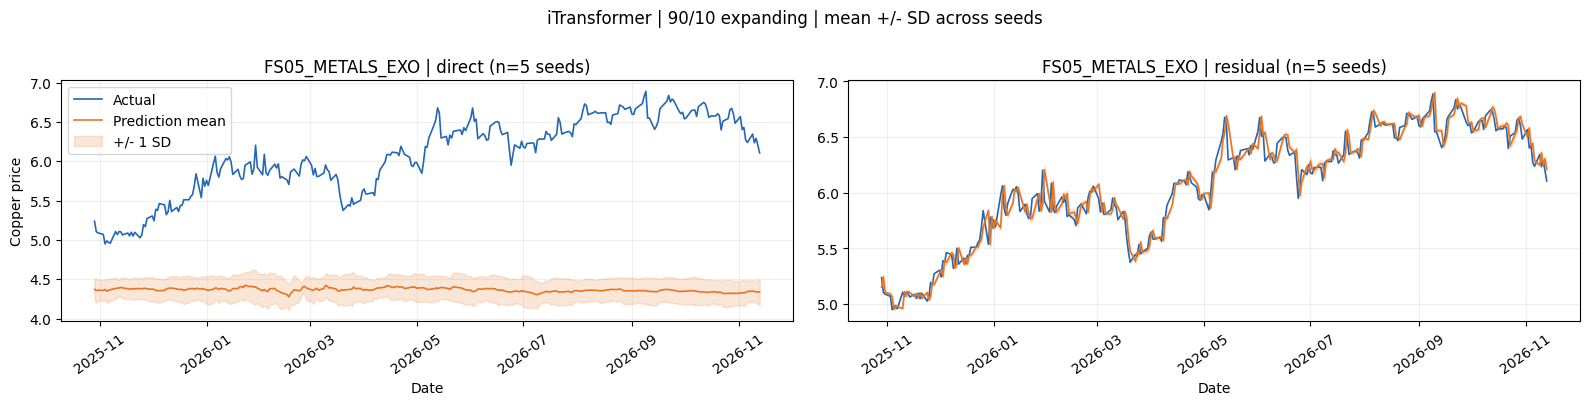

Figure: /kaggle/working/iTransformer_FS05_5Seeds/itransformer_fs05_5seed_ba9f46661575_shaa761a908/figures/itransformer_90_expanding_5seed_overview.png


In [8]:
plot_ratio,plot_scheme=0.90,'expanding'
fig,axes=plt.subplots(len(ACTIVE_FS),2,figsize=(16,4*len(ACTIVE_FS)),squeeze=False)
for i,fs in enumerate(ACTIVE_FS):
    g=raw_predictions[(raw_predictions.feature_set==fs)&np.isclose(raw_predictions.ratio.astype(float),plot_ratio)
                      &(raw_predictions.scheme==plot_scheme)]
    base=g[g.model=='naive'].sort_values('Date')
    for j,model in enumerate(['itransformer_direct','itransformer_residual']):
        ax=axes[i,j]; runs=g[g.model==model]
        ax.plot(base.Date,base.actual,label='Actual',color='#2468b4',lw=1.2)
        if len(runs):
            pivot=runs.pivot(index='Date',columns='seed',values='pred').sort_index()
            avg=pivot.mean(axis=1); sd=pivot.std(axis=1,ddof=1)
            ax.plot(avg.index,avg.values,label='Prediction mean',color='#e87522',lw=1.2)
            if pivot.shape[1]>1: ax.fill_between(avg.index,(avg-sd).values,(avg+sd).values,
                                                   color='#e87522',alpha=.18,label='+/- 1 SD')
            ax.set_title(f'{fs} | {model.replace("itransformer_", "")} (n={pivot.shape[1]} seeds)')
        else: ax.set_title(f'{fs} | {model} (no completed seed)')
        ax.grid(alpha=.2); ax.tick_params(axis='x',rotation=35)
        if i==0 and j==0: ax.legend()
        if j==0: ax.set_ylabel('Copper price')
        if i==len(ACTIVE_FS)-1: ax.set_xlabel('Date')
fig.suptitle('iTransformer | 90/10 expanding | mean +/- SD across seeds',y=1.002)
fig.tight_layout()
fig_path=OUT/'figures'/'itransformer_90_expanding_5seed_overview.png'
fig.savefig(fig_path,dpi=160,bbox_inches='tight'); plt.show()
print('Figure:',fig_path)

## 9. Package outputs and checkpoints for download

Creates or refreshes the Kaggle ZIP containing completed job predictions, histories, and aggregate tables. The ZIP is also refreshed by the training cell every 40 fits for recovery.


In [9]:
zip_path=save_resume_zip()
status=json.loads((OUT/'run_status.json').read_text(encoding='utf-8'))
print('ZIP saved to Kaggle Output:',zip_path)
print('Run state:',status.get('state'),
      '| neural:',status.get('completed_neural_fits'),'/',status.get('expected_neural_fits'),
      '| Naive:',status.get('completed_naive_baselines'),'/',status.get('expected_naive_baselines'))
print('Main tables:',OUT/'raw_predictions.csv',OUT/'metrics_mean_std.csv',OUT/'seed42_predictions.csv')


ZIP saved to Kaggle Output: /kaggle/working/iTransformer_FS05_5Seeds_ba9f46661575.zip
Run state: complete | neural: 120 / 120 | Naive: 12 / 12
Main tables: /kaggle/working/iTransformer_FS05_5Seeds/itransformer_fs05_5seed_ba9f46661575_shaa761a908/raw_predictions.csv /kaggle/working/iTransformer_FS05_5Seeds/itransformer_fs05_5seed_ba9f46661575_shaa761a908/metrics_mean_std.csv /kaggle/working/iTransformer_FS05_5Seeds/itransformer_fs05_5seed_ba9f46661575_shaa761a908/seed42_predictions.csv


## How to run

1. Attach the same Kaggle dataset containing `dataset_9_commodities_daily.csv`, enable a GPU, and run the notebook from the top. This notebook is pinned to FS05 and seeds 41–45.
2. The training cell processes every remaining job (`MAX_NEW_FITS = None`): **120 neural fits plus 12 Naive baselines**. It checkpoints completed jobs and refreshes the recovery ZIP every 40 neural fits.
3. If interrupted while the Kaggle working directory survives, rerun the training cell. If the session reset, download the latest `iTransformer_FS05_5Seeds_*.zip` from Kaggle Output, attach it as an input, set `RESUME_ZIP_PATH` to that ZIP, and run from the top. Use the same dataset and configuration.
4. Confirm `run_status.json` says `state: complete`, `completed_neural_fits: 120`, and `completed_naive_baselines: 12`. Then run the aggregation, plot, and package cells.

**Main outputs:** per-job histories and CSV checkpoints, `raw_predictions.csv`, `seed42_predictions.csv`, `seed42_metrics.csv`, `metrics_by_seed.csv`, `metrics_mean_std.csv`, Naive metrics, DM tables, plots, and the recovery ZIP.

The notebook saves results after each completed fit, but does not save model weights mid-epoch. An interrupted fit is restarted from its beginning when resumed.
